importing all libriers that will be used for this analysis




In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


# READING AND EXPLORING MY DATASET

In [60]:
path = "/content/Wholesale customers data.csv"
wholesale = pd.read_csv(path)
wholesale

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


In [61]:
"""checking the dimensions of the dataset"""

wholesale.shape


(440, 8)

In [62]:
wholesale.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen'],
      dtype='object')

In [63]:
wholesale.dtypes

,0
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


In [64]:
wholesale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [65]:
wholesale.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


#DATA QUALITY CHECKS

In [66]:
wholesale.isnull().sum()

,0
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


In [67]:
wholesale.duplicated().sum()

np.int64(0)

In [68]:
wholesale[["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]].min()

,0
Fresh,3
Milk,55
Grocery,3
Frozen,25
Detergents_Paper,3
Delicassen,3


In [69]:
wholesale[["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]].max()

,0
Fresh,112151
Milk,73498
Grocery,92780
Frozen,60869
Detergents_Paper,40827
Delicassen,47943


#EXPOLRATIVE ANALYSIS

In [70]:
"""EXPLORING THE MILK COLUNM MORE DEEPLY, I WLL FIRST BE INVESTIGATING THE MEAN, MEDIAN AND MODE"""

wholesale["Milk"].mean()

np.float64(5796.265909090909)

In [71]:

wholesale["Milk"].median()

3627.0

In [72]:
# Calculate the spread (range) of the Milk column
spread = wholesale["Milk"].max() - wholesale["Milk"].min()
spread

"""i realized that the mean is higher than the median, which suggest that
the distribution may be righly skwed, i will like to investigate more
to see where most values cluster"""

'i realized that the mean is higher than the median, which suggest that\nthe distribution may be righly skwed, i will like to investigate more\nto see where most values cluster'

#FURTHER INVESTIGATION ON THE MILK COLUNM

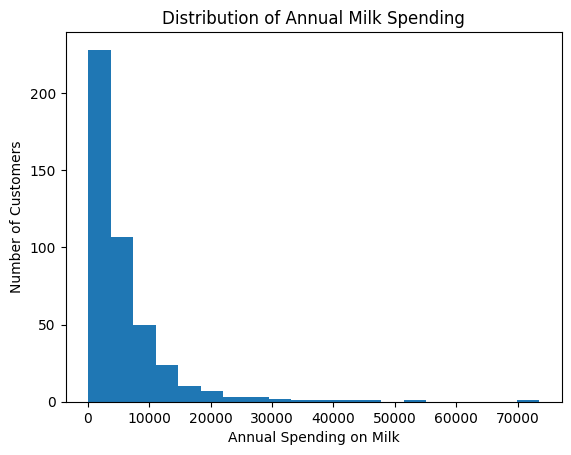

In [73]:
#Creating a histogram to further investigate the milk colunm


plt.hist(wholesale['Milk'], bins=20)
plt.xlabel('Annual Spending on Milk')
plt.ylabel('Number of Customers')
plt.title('Distribution of Annual Milk Spending')
plt.show()



In [74]:
#the histogram suggests that some customers have unusually high spending,
#but it doesn't establish which observations qualify as statistical
 #outliers. Nor does it tell us why those customers spend more.

"""my next step is to investigate whether the Milk column contains potential
outliers using the interquartile range (IQR) method."""


'my next step is to investigate whether the Milk column contains potential\noutliers using the interquartile range (IQR) method.'

In [75]:
IQR = wholesale["Milk"].quantile(0.75) - wholesale['Milk'].quantile(0.25)
IQR

np.float64(5657.25)

In [76]:
lower_bound = wholesale['Milk'].quantile(0.25) - 1.5 * IQR
upper_bound = wholesale['Milk'].quantile(0.75) + 1.5 * IQR
print(lower_bound)
print(upper_bound)

-6952.875
15676.125


In [77]:
# FINDING OUT HOW MANY OBSERVATIONS ARE GREATER THAN 15,676.125

milk_outliers = wholesale[wholesale['Milk'] > 15676.125]

milk_outliers


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
23,2,3,26373,36423,22019,5154,4337,16523
28,2,3,4113,20484,25957,1158,8604,5206
38,2,3,4591,15729,16709,33,6956,433
45,2,3,5181,22044,21531,1740,7353,4985
47,2,3,44466,54259,55571,7782,24171,6465
49,2,3,4967,21412,28921,1798,13583,1163
56,2,3,4098,29892,26866,2616,17740,1340
61,2,3,35942,38369,59598,3254,26701,2017
65,2,3,85,20959,45828,36,24231,1423
85,2,3,16117,46197,92780,1026,40827,2944


In [78]:
# COUNTNG THE TOTAL NUMBER OF THE OBSERVATIONS GREATER THAN 15,676.125


len(milk_outliers)

28

In [79]:
# next steps: calulating the mean and median for the full milk colunm alone.

wholesale["Milk"].mean()

np.float64(5796.265909090909)

In [80]:
wholesale["Milk"].median()

3627.0

In [81]:
## filtering out values of observations that exceed  my upper bound limit

milk_filtered = wholesale.loc[wholesale['Milk'] <= 15676.125, 'Milk']
milk_filtered

,Milk
0,9656
1,9810
2,8808
3,1196
4,5410
...,...
435,12051
436,1431
437,15488
438,1981


In [82]:
# finding out the mean of the fillterd observations
milk_filtered.mean()

np.float64(4326.332524271845)

In [83]:
# finding out the meian of the filterd observations

milk_filtered.median()

3327.5

In [84]:
# now i want to chec the descriptive statistics for all the categorical colunms so i can investigate further

wholesale[["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]].describe()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


In [85]:
#this shows that Fresh has the greatest absolute variation in spending,
# with a standard deviation of approximately 12,647.
# WHICH WILL LEAD ME TO MEASURING THE COEFFIECNT OF VARIATION.


""" NOW I WANT TO MEASURE THE CV FOR FRESH, AND MILK AND COMPARE MY VALUES"""



' NOW I WANT TO MEASURE THE CV FOR FRESH, AND MILK AND COMPARE MY VALUES'

In [86]:
Fresh_CV = (wholesale["Fresh"].std() / wholesale["Fresh"].mean()) * 100
Fresh_CV

np.float64(105.39179237473148)

In [87]:
Milk_CV = (wholesale["Milk"].std() / wholesale["Milk"].mean()) *100
Milk_CV

np.float64(127.32985840065413)

In [88]:
# now i want to find the CV for the rest of the colunms

Grocery_cv = (wholesale["Grocery"].std()/ wholesale["Grocery"].mean()) * 100
Grocery_cv

np.float64(119.51743730016824)

In [89]:
Frozen_cv = (wholesale["Frozen"].std()/ wholesale["Frozen"].mean()) * 100
Frozen_cv

np.float64(158.03323836352914)

In [91]:
Detergents_Paper_cv = (wholesale["Detergents_Paper"].std()/ wholesale["Detergents_Paper"].mean()) * 100
Detergents_Paper_cv

np.float64(165.46471385005154)

In [93]:
Detergents_Paper_cv = (wholesale["Detergents_Paper"].std()/ wholesale["Detergents_Paper"].mean()) * 100
Detergents_Paper_cv

np.float64(165.46471385005154)

In [92]:
Delicassen_cv = (wholesale["Delicassen"].std()/ wholesale["Delicassen"].mean()) * 100
Delicassen_cv

np.float64(184.94068981158384)

# FINDING OUTLIERS IN THE DELICASSEN CATEGORY


In [94]:
IQR = wholesale["Delicassen"].quantile(0.75) - wholesale['Delicassen'].quantile(0.25)
IQR

np.float64(1412.0)

In [95]:
lower_bound = wholesale['Delicassen'].quantile(0.25) - 1.5 * IQR
upper_bound = wholesale['Delicassen'].quantile(0.75) + 1.5 * IQR
print(lower_bound)
print(upper_bound)

-1709.75
3938.25


In [97]:
# finding out the outliers i have

Deli = wholesale[wholesale['Delicassen'] > 3938.25]

Deli

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
2,2,3,6353,8808,7684,2405,3516,7844
4,2,3,22615,5410,7198,3915,1777,5185
17,1,3,5876,6157,2933,839,370,4478
22,1,3,31276,1917,4469,9408,2381,4334
23,2,3,26373,36423,22019,5154,4337,16523
24,2,3,22647,9776,13792,2915,4482,5778
28,2,3,4113,20484,25957,1158,8604,5206
36,1,3,29955,4362,5428,1729,862,4626
40,1,3,24025,4332,4757,9510,1145,5864
45,2,3,5181,22044,21531,1740,7353,4985


In [98]:
# COUNTNG THE TOTAL NUMBER OF THE OBSERVATIONS GREATER THAN 3938.25


len(Deli)

27

In [100]:
## filtering out values of observations that exceed  my upper bound limit

deli_filtered = wholesale.loc[wholesale['Delicassen'] <= 3938.25, 'Delicassen']
deli_filtered

,Delicassen
0,1338
1,1776
3,1788
5,1451
6,545
...,...
435,2204
436,2346
437,1867
438,2125


In [101]:
deli_filtered.mean()

np.float64(1092.0629539951574)

In [102]:
deli_filtered.median()

838.0

In [103]:
wholesale["Delicassen"].mean()

np.float64(1524.8704545454545)

In [104]:
wholesale["Delicassen"].median()

965.5